# KNN Model with Shared TF-IDF Features

## Import and load datasets

In [42]:
from pathlib import Path

import joblib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from scipy.sparse import vstack
from sklearn.neighbors import KNeighborsClassifier
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    classification_report,
    confusion_matrix,
    ConfusionMatrixDisplay
)

PROJECT_ROOT = Path("../..")

DATA_DIR = PROJECT_ROOT / "data"
PROCESSED_DIR = DATA_DIR / "processed"

MODELS_DIR = PROJECT_ROOT / "models"
TFIDF_MODEL_DIR = MODELS_DIR / "tfidf"


train = pd.read_csv(PROCESSED_DIR / "train.csv")
validation = pd.read_csv(PROCESSED_DIR / "validation.csv")
test = pd.read_csv(PROCESSED_DIR / "test.csv")

print("Train:", train.shape)
print("Validation:", validation.shape)
print("Test:", test.shape)

Train: (58823, 6)
Validation: (12611, 6)
Test: (12632, 6)


## Create TF-IDF features

In [43]:
vectorizer = joblib.load(
    TFIDF_MODEL_DIR / "tfidf_vectorizer.joblib"
)

X_train = vectorizer.transform(train["text"].astype(str))
X_validation = vectorizer.transform(validation["text"].astype(str))
X_test = vectorizer.transform(test["text"].astype(str))

y_train = train["target"].astype(int)
y_validation = validation["target"].astype(int)
y_test = test["target"].astype(int)

print("Training features:", X_train.shape)
print("Validation features:", X_validation.shape)
print("Test features:", X_test.shape)

Training features: (58823, 100000)
Validation features: (12611, 100000)
Test features: (12632, 100000)


## Train and tune KNN

In [44]:
# Try different numbers of neighbors and voting methods.
K_VALUES = [3, 5, 7, 11, 15, 21]

results = []

for weights in ["uniform", "distance"]:
    for k in K_VALUES:
        print(f"Testing k={k}, weights={weights}...")

        knn = KNeighborsClassifier(
            n_neighbors=k,
            weights=weights,
            metric="cosine",
            algorithm="brute",
            n_jobs=-1
        )

        knn.fit(X_train, y_train)
        predictions = knn.predict(X_validation)

        results.append({
            "k": k,
            "weights": weights,
            "accuracy": accuracy_score(y_validation, predictions),
            "macro_f1": f1_score(
                y_validation,
                predictions,
                average="macro"
            )
        })

validation_results = pd.DataFrame(results)

# Display results from best to worst.
validation_results = validation_results.sort_values(
    ["macro_f1", "accuracy"],
    ascending=False
)

print(validation_results.to_string(index=False))

# Select the best configuration using validation performance.
best = validation_results.iloc[0]

best_k = int(best["k"])
best_weights = best["weights"]

print("\nBest K:", best_k)
print("Best weights:", best_weights)
print("Best validation macro F1:", best["macro_f1"])

Testing k=3, weights=uniform...
Testing k=5, weights=uniform...
Testing k=7, weights=uniform...
Testing k=11, weights=uniform...
Testing k=15, weights=uniform...
Testing k=21, weights=uniform...
Testing k=3, weights=distance...
Testing k=5, weights=distance...
Testing k=7, weights=distance...
Testing k=11, weights=distance...
Testing k=15, weights=distance...
Testing k=21, weights=distance...
 k  weights  accuracy  macro_f1
21 distance  0.893188  0.882828
21  uniform  0.883197  0.872312
15 distance  0.881294  0.870737
15  uniform  0.870193  0.859306
11 distance  0.869796  0.858964
11  uniform  0.857902  0.846869
 7 distance  0.851400  0.840835
 5 distance  0.844104  0.833780
 7  uniform  0.839426  0.828985
 3 distance  0.833558  0.823574
 5  uniform  0.831972  0.821879
 3  uniform  0.823091  0.813314

Best K: 21
Best weights: distance
Best validation macro F1: 0.8828278118722422


## Trying larger K values

In [45]:
# Experiment: larger K values with distance-weighted voting.

LARGER_K_VALUES = [31, 41, 51, 75, 101, 151]

larger_k_results = []

for k in LARGER_K_VALUES:
    print(f"Testing k={k}...")

    knn = KNeighborsClassifier(
        n_neighbors=k,
        weights="distance",
        metric="cosine",
        algorithm="brute",
        n_jobs=-1
    )

    knn.fit(X_train, y_train)
    predictions = knn.predict(X_validation)

    larger_k_results.append({
        "k": k,
        "weights": "distance",
        "accuracy": accuracy_score(y_validation, predictions),
        "macro_f1": f1_score(
            y_validation,
            predictions,
            average="macro"
        )
    })

larger_k_results_df = pd.DataFrame(larger_k_results)

# Combine with previous tuning results.
all_results = pd.concat(
    [validation_results, larger_k_results_df],
    ignore_index=True
)

all_results = all_results.sort_values(
    ["macro_f1", "accuracy"],
    ascending=False
)

print(all_results.to_string(index=False))

best = all_results.iloc[0]
best_k = int(best["k"])
best_weights = best["weights"]

print("\nBest K:", best_k)
print("Best weights:", best_weights)
print("Best validation accuracy:", best["accuracy"])
print("Best validation macro F1:", best["macro_f1"])

Testing k=31...
Testing k=41...
Testing k=51...
Testing k=75...
Testing k=101...
Testing k=151...
  k  weights  accuracy  macro_f1
151 distance  0.932043  0.922536
101 distance  0.930061  0.920748
 75 distance  0.925858  0.916519
 51 distance  0.917849  0.908050
 41 distance  0.911189  0.901015
 31 distance  0.904766  0.894534
 21 distance  0.893188  0.882828
 21  uniform  0.883197  0.872312
 15 distance  0.881294  0.870737
 15  uniform  0.870193  0.859306
 11 distance  0.869796  0.858964
 11  uniform  0.857902  0.846869
  7 distance  0.851400  0.840835
  5 distance  0.844104  0.833780
  7  uniform  0.839426  0.828985
  3 distance  0.833558  0.823574
  5  uniform  0.831972  0.821879
  3  uniform  0.823091  0.813314

Best K: 151
Best weights: distance
Best validation accuracy: 0.9320434541273491
Best validation macro F1: 0.9225362981538583


## Trying even larger K values

In [46]:
# Experiment: even larger neighborhoods.
MORE_K_VALUES = [201, 301, 501, 751, 1001]

more_k_results = []

for k in MORE_K_VALUES:
    print(f"Testing k={k}...")

    knn = KNeighborsClassifier(
        n_neighbors=k,
        weights="distance",
        metric="cosine",
        algorithm="brute",
        n_jobs=-1
    )

    knn.fit(X_train, y_train)
    predictions = knn.predict(X_validation)

    more_k_results.append({
        "k": k,
        "weights": "distance",
        "accuracy": accuracy_score(y_validation, predictions),
        "macro_f1": f1_score(
            y_validation,
            predictions,
            average="macro"
        )
    })

more_k_results_df = pd.DataFrame(more_k_results)

# Combine with all previous tuning results.
all_results = pd.concat(
    [all_results, more_k_results_df],
    ignore_index=True
)

all_results = all_results.sort_values(
    ["macro_f1", "accuracy"],
    ascending=False
)

print(all_results.to_string(index=False))

best = all_results.iloc[0]
best_k = int(best["k"])
best_weights = best["weights"]

print("\nBest K:", best_k)
print("Best weights:", best_weights)
print("Best validation accuracy:", best["accuracy"])
print("Best validation macro F1:", best["macro_f1"])

Testing k=201...
Testing k=301...
Testing k=501...
Testing k=751...
Testing k=1001...
   k  weights  accuracy  macro_f1
 301 distance  0.935215  0.925342
 501 distance  0.934184  0.923362
 151 distance  0.932043  0.922536
 201 distance  0.931885  0.921977
 751 distance  0.932995  0.921297
 101 distance  0.930061  0.920748
1001 distance  0.929823  0.916932
  75 distance  0.925858  0.916519
  51 distance  0.917849  0.908050
  41 distance  0.911189  0.901015
  31 distance  0.904766  0.894534
  21 distance  0.893188  0.882828
  21  uniform  0.883197  0.872312
  15 distance  0.881294  0.870737
  15  uniform  0.870193  0.859306
  11 distance  0.869796  0.858964
  11  uniform  0.857902  0.846869
   7 distance  0.851400  0.840835
   5 distance  0.844104  0.833780
   7  uniform  0.839426  0.828985
   3 distance  0.833558  0.823574
   5  uniform  0.831972  0.821879
   3  uniform  0.823091  0.813314

Best K: 301
Best weights: distance
Best validation accuracy: 0.935215288240425
Best validation ma

## Fine tuning around best K value so far

In [47]:
# Fine-tune K around the current best value.

FINE_K_VALUES = [225, 250, 275, 325, 350, 375, 400, 450]

fine_k_results = []

for k in FINE_K_VALUES:
    print(f"Testing k={k}...")

    knn = KNeighborsClassifier(
        n_neighbors=k,
        weights="distance",
        metric="cosine",
        algorithm="brute",
        n_jobs=-1
    )

    knn.fit(X_train, y_train)
    predictions = knn.predict(X_validation)

    fine_k_results.append({
        "k": k,
        "weights": "distance",
        "accuracy": accuracy_score(y_validation, predictions),
        "macro_f1": f1_score(
            y_validation,
            predictions,
            average="macro"
        )
    })

fine_k_results_df = pd.DataFrame(fine_k_results)

# Add these results to previous experiments.
all_results = pd.concat(
    [all_results, fine_k_results_df],
    ignore_index=True
)

# Sort by macro F1, then accuracy.
all_results = all_results.sort_values(
    ["macro_f1", "accuracy"],
    ascending=False
)

print(all_results.head(15).to_string(index=False))

best = all_results.iloc[0]

best_k = int(best["k"])
best_weights = best["weights"]

print("\nBest K:", best_k)
print("Best weights:", best_weights)
print("Best validation accuracy:", best["accuracy"])
print("Best validation macro F1:", best["macro_f1"])

Testing k=225...
Testing k=250...
Testing k=275...
Testing k=325...
Testing k=350...
Testing k=375...
Testing k=400...
Testing k=450...
   k  weights  accuracy  macro_f1
 275 distance  0.935374  0.925692
 301 distance  0.935215  0.925342
 350 distance  0.935374  0.925336
 325 distance  0.934898  0.924907
 250 distance  0.934026  0.924177
 375 distance  0.934184  0.923771
 501 distance  0.934184  0.923362
 225 distance  0.932995  0.923129
 400 distance  0.933629  0.923071
 450 distance  0.933709  0.923000
 151 distance  0.932043  0.922536
 201 distance  0.931885  0.921977
 751 distance  0.932995  0.921297
 101 distance  0.930061  0.920748
1001 distance  0.929823  0.916932

Best K: 275
Best weights: distance
Best validation accuracy: 0.9353738799460788
Best validation macro F1: 0.9256924784387981


## Tuning classification threshold

In [48]:
# Tune the classification threshold using validation data.

best_knn = KNeighborsClassifier(
    n_neighbors=best_k,
    weights=best_weights,
    metric="cosine",
    algorithm="brute",
    n_jobs=-1
)

best_knn.fit(X_train, y_train)

# Probability of ChatGPT (class 1).
chatgpt_index = list(best_knn.classes_).index(1)

validation_probs = best_knn.predict_proba(X_validation)[:, chatgpt_index]

threshold_results = []

for threshold in np.arange(0.30, 0.81, 0.025):
    predictions = (validation_probs >= threshold).astype(int)

    threshold_results.append({
        "threshold": round(float(threshold), 3),
        "accuracy": accuracy_score(y_validation, predictions),
        "macro_f1": f1_score(
            y_validation,
            predictions,
            average="macro"
        )
    })

threshold_results_df = pd.DataFrame(threshold_results)

threshold_results_df = threshold_results_df.sort_values(
    ["macro_f1", "accuracy"],
    ascending=False
)

print(threshold_results_df.head(15).to_string(index=False))

best_threshold = float(
    threshold_results_df.iloc[0]["threshold"]
)

print("\nBest K:", best_k)
print("Best weights:", best_weights)
print("Best threshold:", best_threshold)
print(
    "Best validation macro F1:",
    threshold_results_df.iloc[0]["macro_f1"]
)

 threshold  accuracy  macro_f1
     0.475  0.935532  0.926935
     0.500  0.935374  0.925692
     0.450  0.931488  0.923588
     0.525  0.932599  0.921107
     0.425  0.923876  0.916278
     0.550  0.925779  0.911611
     0.400  0.906986  0.899195
     0.575  0.916660  0.899027
     0.600  0.905400  0.883040
     0.375  0.882563  0.874780
     0.625  0.893585  0.865791
     0.650  0.881373  0.847361
     0.350  0.847752  0.840613
     0.675  0.865435  0.822870
     0.325  0.809849  0.804085

Best K: 275
Best weights: distance
Best threshold: 0.475
Best validation macro F1: 0.9269347169597125


## Train final model and evaluate

In [49]:
X_train_validation = vstack(
    [X_train, X_validation]
)

y_train_validation = pd.concat(
    [y_train, y_validation],
    ignore_index=True,
)

final_knn = KNeighborsClassifier(
    n_neighbors=best_k,
    weights=best_weights,
    metric="cosine",
    algorithm="brute",
    n_jobs=-1
)

final_knn.fit(X_train_validation, y_train_validation)

# Get the distance-weighted vote score for ChatGPT (class 1).
chatgpt_index = list(final_knn.classes_).index(1)

test_probs = final_knn.predict_proba(X_test)[:, chatgpt_index]

# Apply the best threshold selected using validation data.
test_predictions = (test_probs >= best_threshold).astype(int)

print("Accuracy:", accuracy_score(y_test, test_predictions))
print("Precision:", precision_score(
    y_test, test_predictions, average="macro", zero_division=0
))
print("Recall:", recall_score(
    y_test, test_predictions, average="macro", zero_division=0
))
print("Macro F1:", f1_score(
    y_test, test_predictions, average="macro", zero_division=0
))

print(classification_report(
    y_test,
    test_predictions,
    target_names=["Human", "ChatGPT"],
    zero_division=0
))

Accuracy: 0.9343730208993034
Precision: 0.9188098305212297
Recall: 0.9353483726105267
Macro F1: 0.9262206835549895
              precision    recall  f1-score   support

       Human       0.97      0.93      0.95      8579
     ChatGPT       0.87      0.94      0.90      4053

    accuracy                           0.93     12632
   macro avg       0.92      0.94      0.93     12632
weighted avg       0.94      0.93      0.94     12632



## Confusion matrix

[[8001  578]
 [ 251 3802]]


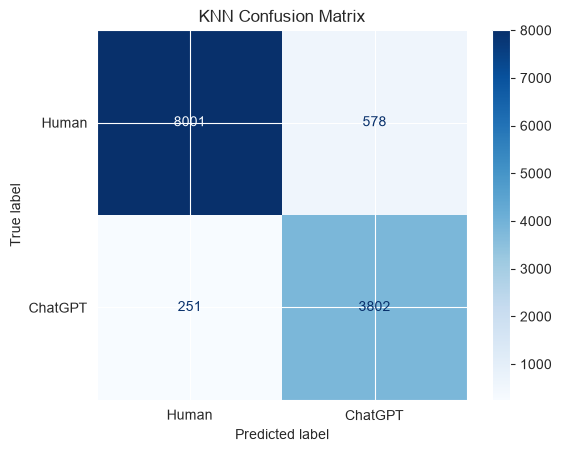

In [50]:
cm = confusion_matrix(
    y_test,
    test_predictions,
    labels=[0, 1]
)

print(cm)

ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=["Human", "ChatGPT"]
).plot(cmap="Blues", values_format="d")

plt.title("KNN Confusion Matrix")
plt.show()

## Save model

In [52]:
import joblib

model_path = TFIDF_MODEL_DIR / "knn_model.joblib"

# Save the trained model, vectorizer, and configuration.
model_data = {
    "model": final_knn,
    "vectorizer": "tfidf_vectorizer.joblib",
    "config": {
        "n_neighbors": best_k,
        "weights": best_weights,
        "threshold": best_threshold,
        "metric": "cosine",
        "algorithm": "brute"
    }
}

joblib.dump(model_data, model_path)

print("Saved model to:", model_path)

Saved model to: ../../models/tfidf/knn_model.joblib
